In [8]:

from functions import *
df = pd.read_excel("../data/raw/NIMS_FATIGUE.xlsx")
print(df.shape)
print(df.columns.tolist())

(2793, 20)
['Heat', 'Testing Material', 'DS No. PDF', 'Reduction Ratio', 'dA', 'dB', 'dC', 'Normalizing temp', 'Quenching temp', 'Tempering temp', 'Upper yield stress', '0.2% proof stress ', 'Tensile strength', 'True fracture stress', 'Elongation', 'Reduction of area', 'Vickers hardness', 'Type of test', 'σa', 'Nf']


In [6]:
x = df.drop(columns=['Nf'])
y = df['Nf']
print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: (2793, 19)
y shape: (2793,)


In [11]:
# Count missing values in each inpuut
# to identify columns that need preprocessing
missing_values = df.isnull().sum()
print("Missing values in each column:", missing_values)
# Display the data type of each input to help identify categorical columns that need encoding.
print(x.dtypes)

Missing values in each column: Heat                      0
Testing Material          0
DS No. PDF                0
Reduction Ratio           0
dA                        0
dB                        0
dC                        0
Normalizing temp         71
Quenching temp          336
Tempering temp          336
Upper yield stress      145
0.2% proof stress         0
Tensile strength          0
True fracture stress    145
Elongation                0
Reduction of area         0
Vickers hardness          0
Type of test              0
σa                        0
Nf                        0
dtype: int64
Heat                        str
Testing Material            str
DS No. PDF                int64
Reduction Ratio           int64
dA                      float64
dB                      float64
dC                      float64
Normalizing temp        float64
Quenching temp          float64
Tempering temp          float64
Upper yield stress      float64
0.2% proof stress         int64
Tensile stre

In [16]:
# Select columns with the object data type and display their names and example values.
object_columns = x.select_dtypes(include=['object']).columns
print("object columns:", object_columns.tolist())
for col in object_columns:
    print(f"\n{col}:")
    print(x[col].unique()[:10])

object columns: ['Heat', 'Testing Material', 'Type of test']

Heat:
<StringArray>
['A', 'B', 'C', 'D', 'E', 'F', 'H', 'I', 'J', 'K']
Length: 10, dtype: str

Testing Material:
<StringArray>
['S25C', 'S35C', 'S40C', 'S45C', 'S55C']
Length: 5, dtype: str

Type of test:
<StringArray>
['Rotating bending', 'Uniaxial loading']
Length: 2, dtype: str


C:\Users\Leili\AppData\Local\Temp\ipykernel_7908\1558885827.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_columns = x.select_dtypes(include=['object']).columns


In [17]:
# count the number of unique values in each categorical feature. this helps to undrestand which feature may require encoding.
categorical_columns = ["Heat", "Testing Material", "Type of test"]
for col in categorical_columns:
    print(f"{col}: {x[col].nunique()} unique values")

Heat: 12 unique values
Testing Material: 5 unique values
Type of test: 2 unique values


Target variable analysis
to examine the distribution of the target variavle(Nf) which represents the number of cycles to failure. this helps to undrestand the range and variation in fatigue lifetime before selecting regression models.

In [18]:
# display summary statistics for the target variable(Nf) to help undrestand the range and distribution of fatigue lifetime.
print(y.describe())

count    2.793000e+03
mean     6.945012e+07
std      6.936210e+08
min      1.010000e+04
25%      1.680000e+05
50%      5.260000e+05
75%      1.000000e+07
max      1.000000e+10
Name: Nf, dtype: float64


Distribution of fatigue lifetime using a histogram.since Nf values vary over a wide range we use a logarithmic transformation to make the distribution easier to undrestand and assess its suitability for regression modeling.

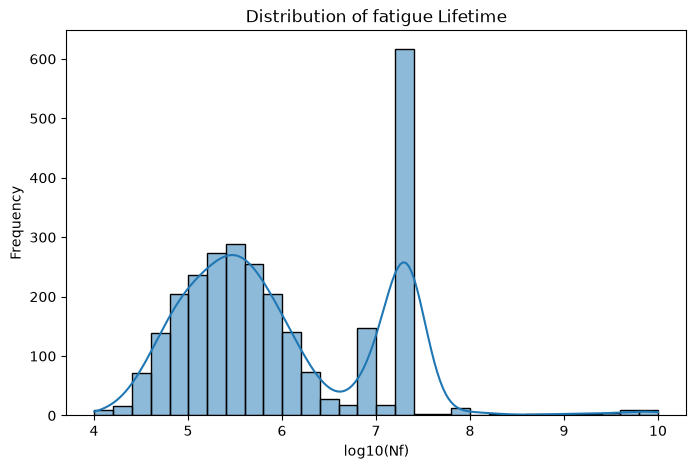

In [19]:
# transform Nf using Log10 to reduce the scale of large values.
log_nf = np.log10(y)
plt.figure(figsize=(8, 5))
sns.histplot(log_nf, bins=30, kde=True)
plt.title('Distribution of fatigue Lifetime')
plt.xlabel("log10(Nf)")
plt.ylabel("Frequency")

plt.show()